# Pass-archive cleaning: median of the quality-screened top 15

**Question.** Does aggregating the top 15 quality-screened Sentinel-2 passes per month produce more stable maize predictors than using only the highest-ranked pass?

This notebook reads the team's **unfiltered** `passarchive_v1.duckdb` (Kenya, Malawi, Zimbabwe), works across both archived years, and makes a matched pair of feature arms: `median_top15` and `best1`. It uses the previously developed local cloud, band, timing and pixel-quality screen **and its original top-15 ranking**. The image decision never uses yield. Field labels are joined only after all image features are fixed.

The pipeline is: original local cloud and field-pixel screen → original top-15 ranking → reflectance conversion → per-band median of the selected images → season summary. The original ranking prioritizes independent overflights and may fill remaining slots with another product from an overflight. **No selected image is dropped or re-ranked here.** A month with fewer than 15 qualifying images is retained with its support count. Missing months stay missing; the model must impute and scale *inside each training fold*. This notebook does **not** choose a winning model.

In [1]:
from pathlib import Path
import json, shutil, subprocess, sys
import duckdb, pandas as pd, numpy as np
import matplotlib.pyplot as plt

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'data/passarchive_v1/release/DICTIONARY.md').is_file()), None)
assert ROOT is not None, 'Launch from within the repository'
DB = ROOT / 'data/passarchive_v1/release/passarchive_v1.duckdb'
SCREEN = ROOT / 'data/features/top15_screen_both_maize'
OUT = ROOT / 'data/features/top15_median'
HANDOFF = ROOT / 'data/passarchive_v1/cleaning'
assert DB.is_file(), 'Put the checksum-verified archive in the path specified by docs/DATA_SETUP.md'
print('Database: data/passarchive_v1/release/passarchive_v1.duckdb')
print('Bytes:', DB.stat().st_size)

Database: data/passarchive_v1/release/passarchive_v1.duckdb
Bytes: 2678075392


## 1. What the source actually contains

The archive includes all maize field-seasons and both the harvest calendar year (`current`) and preceding calendar year (`previous`). We retain both because some growing seasons cross New Year. Recorded planting and harvest dates define a season where both exist and are coherent. Otherwise, the fallback is the harvest calendar year, explicitly flagged as `harvest_calendar_year`; that fallback is only a comparison proxy.

In [2]:
con = duckdb.connect(str(DB), read_only=True)
source = con.execute('''select country_iso3, dataset, count(*) as field_seasons,
    count(*) filter(where planting_date is not null and harvest_date is not null) as both_dates,
    count(*) filter(where usable_at_field_scale) as field_scale_usable
    from fields where crop='maize' group by 1,2 order by 1,2''').df()
con.close()
print(source.to_string(index=False))

country_iso3                        dataset  field_seasons  both_dates  field_scale_usable
         KEN          one_acre_fund_curated            389         294                   0
         KEN             one_acre_fund_full          23674       17061               23159
         MWI                    malawi_2022            529           0                 529
         MWI                    malawi_2023            267           0                 267
         MWI             one_acre_fund_full           2594        1782                1832
         ZWE vision_guided_yield_estimation           5055           0                5055
         ZWE                       zimbabwe           2269        2269                2269


## 2. Local image quality, with no yield labels

The screening script reads the raw pass and pixel tables. It rejects incomplete bands and visibly obstructed point pixels. For polygon fields it checks native SCL pixels inside the stored footprint and requires at least 80% clear vegetation or bare-soil pixels. High local cloud probability and low sun go to review. Whole-scene cloud cover is a weaker ranking signal because it may describe clouds far from the field. Only `keep` images within known crop dates (or with incomplete dates) proceed. **A point observation establishes only the sampled pixel; it cannot prove that the whole field is clear.**

The full screen is cached locally because it is a large intermediate file. To rebuild, this cell runs `select_passarchive_imagery.py` with both archive years and maize only. No raw database values are edited.

In [3]:
if not (SCREEN / 'monthly_top15.parquet').is_file():
    subprocess.run([sys.executable, str(ROOT / 'scripts/quality/select_passarchive_imagery.py'),
                    '--database', str(DB), '--output', str(SCREEN),
                    '--window-kind', 'both', '--crop', 'maize'],
                   cwd=ROOT, check=True)
screen_summary = json.loads((SCREEN / 'summary.json').read_text(encoding='utf-8'))
print({k: screen_summary[k] for k in
       ['scope_fields','candidate_rows','decisions','field_months','window_kind','crop']})

{'scope_fields': 34777, 'candidate_rows': 5427638, 'decisions': {'reject': 1977705, 'review': 66452, 'keep': 3383481}, 'field_months': 834648, 'window_kind': 'both', 'crop': 'maize'}


## 3. Feature aggregation rule

The existing screener ranks qualifying images with its original quality score: 50 points for local clear fraction, 25 for local cloud probability, 10 for whole-scene cloud cover, 10 for recorded crop timing, and 5 for sun elevation. It puts independent overflights first, then can fill up to 15 slots with other clear products. **We do not re-score, replace, or remove any image from that list.** We convert each of the ten model bands from Sentinel-2 digital number with the scene's published offset, `(DN + offset) / 10000`. Out-of-range converted values are reported but do not change the top-15 selection. The `median_top15` arm takes each band's median across the selected images. `best1` uses the highest-ranked image from the same list.

This is a label-free aggregation of the previous selection rule. The score weights were not tuned on held-out yields. Median aggregation can suppress residual contamination but may also smooth genuine rapid crop change; Zida's identical-fold model comparison tests that trade-off.

In [4]:
sys.path.insert(0, str(ROOT / 'scripts/quality'))
from allen_top15_median import build
summary = build(DB, SCREEN / 'monthly_top15.parquet', OUT)
print(json.dumps({k:v for k,v in summary.items() if k!='source_top15'}, indent=2))

{
  "scope": "maize; previous and current archive years",
  "converted_scenes": 1491879,
  "valid_reflectance_scenes": 1491701,
  "out_of_range_reflectance_scenes": 178,
  "selected_scenes": 1491879,
  "monthly_rows": 834648,
  "field_seasons": 34777,
  "model_rows": 69554,
  "window_rule_counts": {
    "harvest_calendar_year": 13427,
    "recorded_dates": 21350
  },
  "model_month_coverage": [
    [
      "KEN",
      "best1",
      24063,
      23098,
      6.36
    ],
    [
      "KEN",
      "median_top15",
      24063,
      23098,
      6.36
    ],
    [
      "MWI",
      "best1",
      3390,
      2628,
      5.28
    ],
    [
      "MWI",
      "median_top15",
      3390,
      2628,
      5.28
    ],
    [
      "ZWE",
      "best1",
      7324,
      7324,
      9.92
    ],
    [
      "ZWE",
      "median_top15",
      7324,
      7324,
      9.92
    ]
  ]
}


## 4. Coverage and actual differences

The two arms have the same field-seasons and observed months. The plot shows how many of the original top-15 images remain per month; the table compares optical features produced by one image versus their median. Differences are data differences, **not** evidence of better yield predictions.

Monthly support after the original top-15 screen (0 = missing):
support            0      1     2-5   6-10  11-15
country_iso3                                     
KEN           395630  33643  126275  19365   2599
MWI            54693   4224   15321   6356    766
ZWE            44248   5619   60677  47686  17546


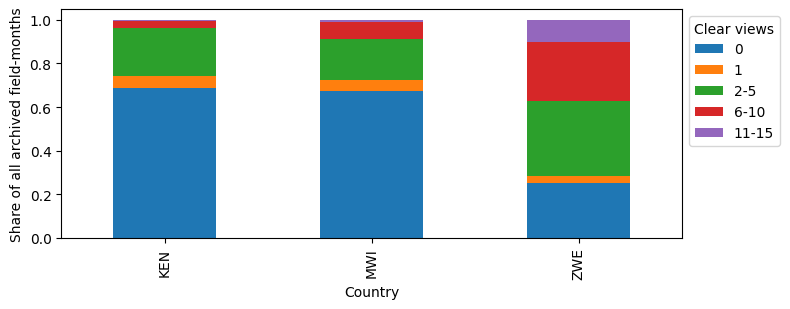

In [5]:
monthly = pd.read_parquet(OUT / 'allen_monthly.parquet',
                          columns=['country_iso3','n_selected_scenes'])
support = (monthly.assign(support=pd.cut(monthly.n_selected_scenes,
              bins=[-1,0,1,5,10,15], labels=['0','1','2-5','6-10','11-15']))
           .groupby(['country_iso3','support']).size().unstack(fill_value=0))
print('Monthly support after the original top-15 screen (0 = missing):')
print(support.to_string())
ax = support.div(support.sum(axis=1),axis=0).plot.bar(stacked=True, figsize=(8,3.2))
ax.set_ylabel('Share of all archived field-months')
ax.set_xlabel('Country')
ax.legend(title='Clear views', bbox_to_anchor=(1,1))
plt.tight_layout()
plt.show()

In [6]:
model = pd.read_parquet(OUT / 'allen_model_ready.parquet')
wide = model.pivot(index='field_season_id',columns='cleaning_arm',
                   values=['b08_mean','ndvi_mean','months_observed'])
for feature in ['b08_mean','ndvi_mean']:
    difference = (wide[(feature,'median_top15')]-wide[(feature,'best1')]).abs()
    print(feature, 'n pairs =',difference.notna().sum(),
          'median absolute difference =',round(difference.median(),4),
          '90th percentile =',round(difference.quantile(.9),4))
print('Season-window rules:')
print(model.loc[model.cleaning_arm=='median_top15','window_rule'].value_counts().to_string())

b08_mean n pairs = 33050 median absolute difference = 0.0061 90th percentile = 0.0182
ndvi_mean n pairs = 33050 median absolute difference = 0.0111 90th percentile = 0.0355
Season-window rules:
window_rule
recorded_dates           21350
harvest_calendar_year    13427


## 5. Quality checks and model handoff

Every field-season appears once per arm. Both arms use the same month coverage. The output carries `field_season_id`, country, dataset, year, location quality, label status, yield in t/ha, ten mean reflectances, NDVI summary and support counts. The labels were joined after cleaning, so they cannot influence scene selection. Zida should use identical fields and spatial folds for both arms, and fit imputation, scaling and Ridge or other baseline **within each training fold**. Keep the existing fold-0 reserve untouched. For a strict field-level analysis, require `usable_at_field_scale` and inspect `label_status`.

In [7]:
assert len(model)==2*model.field_season_id.nunique()
assert not model.duplicated(['field_season_id','cleaning_arm']).any()
assert (wide[('months_observed','median_top15')]==wide[('months_observed','best1')]).all()
assert summary['selected_scenes']==screen_summary['selected_scenes']
print('Original top-15 selected scenes preserved:', summary['selected_scenes'])
print('Selected scenes with an out-of-range converted band:',
      summary['out_of_range_reflectance_scenes'])
assert set(model.cleaning_arm)=={'median_top15','best1'}
HANDOFF.mkdir(parents=True,exist_ok=True)
shutil.copy2(OUT/'allen_model_ready.parquet', HANDOFF/'allen_model_ready.parquet')
print('Checks passed. Shareable model handoff: data/passarchive_v1/cleaning/allen_model_ready.parquet')
print('Rows:',len(model),'Fields:',model.field_season_id.nunique())

Original top-15 selected scenes preserved:

 1491879
Selected scenes with an out-of-range converted band: 178
Checks passed. Shareable model handoff: data/passarchive_v1/cleaning/allen_model_ready.parquet
Rows: 69554 Fields: 34777


### Limits and next comparison

Most Kenyan and Zimbabwe locations are points, so local cloud checks apply to one pixel, not a verified field boundary. Some Malawi and Zimbabwe datasets lack planting/harvest dates; their `harvest_calendar_year` features are a deliberately flagged proxy. A month with zero valid images remains missing. `best1` and `median_top15` preserve the same sample cohort, letting Zida compare the effect of aggregation with the same model and folds. Do not choose this policy using the held-out fold or interpret a larger number of retained images as improved prediction by itself.

Local audit outputs are in `data/features/top15_median/` (ignored by Git). The compact, versioned handoff is `data/passarchive_v1/cleaning/allen_model_ready.parquet`. See `data/passarchive_v1/cleaning/README.md` for the column contract.